<a href="https://colab.research.google.com/github/muhammetozcan07/Multimodal_gas_detection/blob/main/Multimodal_gas_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
from google.colab import drive
import os
import zipfile
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tensorflow.keras import layers, models, regularizers, optimizers, callbacks
from sklearn.metrics import precision_recall_fscore_support



drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/MultimodalGasData/Gas_Sensors_Measurements.csv'
df = pd.read_csv(file_path)

df = df.drop(columns=['Serial Number', 'Corresponding Image Name'])

class_indices = {'NoGas': 0, 'Perfume': 1, 'Smoke': 2, 'Mixture': 3}
df['Gas'] = df['Gas'].map(class_indices)

df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,MQ2,MQ3,MQ5,MQ6,MQ7,MQ8,MQ135,Gas
0,555,515,377,338,666,451,416,0
1,555,516,377,339,666,451,416,0
2,556,517,376,337,666,451,416,0
3,556,516,376,336,665,451,416,0
4,556,516,376,337,665,451,416,0


In [4]:
drive_folder = '/content/drive/MyDrive/MultimodalGasData'
extract_folder = '/content/extracted_images'
os.makedirs(extract_folder, exist_ok=True)

zip_files = ['NoGas.zip', 'Perfume.zip', 'Smoke.zip', 'Mixture.zip']

for zip_name in zip_files:
    zip_path = os.path.join(drive_folder, zip_name)
    if os.path.exists(zip_path):
        print(f"Extracting {zip_name}...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_folder)
    else:
        print(f"WARNING: {zip_path} not found!")

print("All ZIP files extracted successfully!\n")

image_map = {}
for root, dirs, files in os.walk(extract_folder):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')):
            filename_no_ext = os.path.splitext(file)[0]  # e.g., '0_NoGas.png' -> '0_NoGas'
            full_path = os.path.join(root, file)
            image_map[filename_no_ext] = full_path

print(f"Total number of images found: {len(image_map)}")

csv_path = os.path.join(drive_folder, 'Gas_Sensors_Measurements.csv')
df = pd.read_csv(csv_path)

df['Image_Path'] = df['Corresponding Image Name'].map(image_map)

class_indices = {'NoGas': 0, 'Perfume': 1, 'Smoke': 2, 'Mixture': 3}
df['Gas'] = df['Gas'].map(class_indices)

df = df.drop(columns=['Serial Number', 'Corresponding Image Name'])

missing_count = df['Image_Path'].isna().sum()
print(f"Number of unmatched images: {missing_count}")

df.head()

Extracting NoGas.zip...
Extracting Perfume.zip...
Extracting Smoke.zip...
Extracting Mixture.zip...
All ZIP files extracted successfully!

Total number of images found: 6400
Number of unmatched images: 0


,MQ2,MQ3,MQ5,MQ6,MQ7,MQ8,MQ135,Gas,Image_Path
0,555,515,377,338,666,451,416,0,/content/extracted_images/0_NoGas.png
1,555,516,377,339,666,451,416,0,/content/extracted_images/1_NoGas.png
2,556,517,376,337,666,451,416,0,/content/extracted_images/2_NoGas.png
3,556,516,376,336,665,451,416,0,/content/extracted_images/3_NoGas.png
4,556,516,376,337,665,451,416,0,/content/extracted_images/4_NoGas.png


In [5]:

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (128, 128)
image_list = []

print("Loading images into memory...")
for img_path in df['Image_Path']:
    img = load_img(img_path, target_size=IMG_SIZE)
    img_arr = img_to_array(img) / 255.0  # Rescale 1./255
    image_list.append(img_arr)

X_images = np.array(image_list, dtype=np.float32)
X_sensors = df[['MQ2', 'MQ3', 'MQ5', 'MQ6', 'MQ7', 'MQ8', 'MQ135']].values.astype(np.float32)
y_labels = df['Gas'].values.astype(np.int32)

print(f"Loading complete! Image Tensor: {X_images.shape}, Sensor Tensor: {X_sensors.shape}, Labels: {y_labels.shape}")

X_sens_temp, X_sens_test, X_img_temp, X_img_test, y_temp, y_test = train_test_split(
    X_sensors, X_images, y_labels, test_size=0.20, random_state=SEED, stratify=y_labels
)

X_sens_train, X_sens_val, X_img_train, X_img_val, y_train, y_val = train_test_split(
    X_sens_temp, X_img_temp, y_temp, test_size=0.20, random_state=SEED, stratify=y_temp
)

scaler = StandardScaler()
X_sens_train_scaled = scaler.fit_transform(X_sens_train)
X_sens_val_scaled   = scaler.transform(X_sens_val)
X_sens_test_scaled  = scaler.transform(X_sens_test)

X_sens_train_lstm = X_sens_train_scaled.reshape(-1, 1, 7)
X_sens_val_lstm   = X_sens_val_scaled.reshape(-1, 1, 7)
X_sens_test_lstm  = X_sens_test_scaled.reshape(-1, 1, 7)

print("\n--- Data Split Summary ---")
print(f"Train      -> Sensor: {X_sens_train_lstm.shape}, Image: {X_img_train.shape}, Labels: {y_train.shape}")
print(f"Validation -> Sensor: {X_sens_val_lstm.shape}, Image: {X_img_val.shape}, Labels: {y_val.shape}")
print(f"Test       -> Sensor: {X_sens_test_lstm.shape}, Image: {X_img_test.shape}, Labels: {y_test.shape}")

Loading images into memory...
Loading complete! Image Tensor: (6400, 128, 128, 3), Sensor Tensor: (6400, 7), Labels: (6400,)

--- Data Split Summary ---
Train      -> Sensor: (4096, 1, 7), Image: (4096, 128, 128, 3), Labels: (4096,)
Validation -> Sensor: (1024, 1, 7), Image: (1024, 128, 128, 3), Labels: (1024,)
Test       -> Sensor: (1280, 1, 7), Image: (1280, 128, 128, 3), Labels: (1280,)


In [6]:

class_names = ['NoGas', 'Perfume', 'Smoke', 'Mixture']

def evaluate_and_log(model, X_test_input, y_true, model_name, train_time):

    start_inf = time.time()
    y_pred_probs = model.predict(X_test_input, verbose=0)
    total_inf_time = time.time() - start_inf
    latency_ms = (total_inf_time / len(y_true)) * 1000  # ms per sample

    y_pred = np.argmax(y_pred_probs, axis=1)
    acc = accuracy_score(y_true, y_pred)

    print(f"\n==================== {model_name} RESULTS ====================")
    print(f"Test Accuracy             : {acc*100:.2f}%")
    print(f"Total Training Time       : {train_time:.2f} seconds")
    print(f"Inference Latency         : {latency_ms:.3f} ms/sample")
    print(f"Total Parameters          : {model.count_params():,}")
    print("\nClass-wise Metrics :")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=2))

    return y_pred_probs, y_pred, acc, latency_ms

# UNIMODAL GAS SENSOR MODEL (LSTM)

def create_lstm_model():
    inp = layers.Input(shape=(1, 7), name="sensor_input")
    x = layers.LSTM(5, kernel_regularizer=regularizers.l2(0.005), name="lstm_layer")(inp)
    out = layers.Dense(4, activation='softmax', name="lstm_output")(x)
    model = models.Model(inputs=inp, outputs=out, name="LSTM_Only")
    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

lstm_model = create_lstm_model()

print("1/2: Training LSTM Model...")
t0 = time.time()
history_lstm = lstm_model.fit(
    X_sens_train_lstm, y_train,
    validation_data=(X_sens_val_lstm, y_val),
    epochs=150,
    batch_size=32,
    callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)],
    verbose=1
)
lstm_train_time = time.time() - t0

lstm_probs, lstm_preds, lstm_acc, lstm_lat = evaluate_and_log(
    lstm_model, X_sens_test_lstm, y_test, "LSTM (Gas Sensor Only)", lstm_train_time
)


# UNIMODAL THERMAL IMAGE MODEL (CNN)

def create_cnn_model():
    inp = layers.Input(shape=(128, 128, 3), name="image_input")
    reg = regularizers.l1_l2(l1=0.005, l2=0.005)

    x = layers.Conv2D(32, (3, 3), activation='relu', kernel_regularizer=reg)(inp)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(64, (3, 3), activation='relu', kernel_regularizer=reg)(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(128, (3, 3), activation='relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(64, activation='relu')(x)
    out = layers.Dense(4, activation='softmax', name="cnn_output")(x)

    model = models.Model(inputs=inp, outputs=out, name="CNN_Only")
    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.001, weight_decay=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

cnn_model = create_cnn_model()

print("\n2/2: Training CNN Model...")
t0 = time.time()
history_cnn = cnn_model.fit(
    X_img_train, y_train,
    validation_data=(X_img_val, y_val),
    epochs=60,
    batch_size=32,
    callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)],
    verbose=1
)
cnn_train_time = time.time() - t0

cnn_probs, cnn_preds, cnn_acc, cnn_lat = evaluate_and_log(
    cnn_model, X_img_test, y_test, "CNN (Thermal Image Only)", cnn_train_time
)

1/2: Training LSTM Model...
Epoch 1/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4001 - loss: 1.4070 - val_accuracy: 0.6094 - val_loss: 1.3184
Epoch 2/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6975 - loss: 1.2057 - val_accuracy: 0.7129 - val_loss: 1.0979
Epoch 3/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7588 - loss: 0.9900 - val_accuracy: 0.7393 - val_loss: 0.9107
Epoch 4/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7925 - loss: 0.8312 - val_accuracy: 0.7881 - val_loss: 0.7787
Epoch 5/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8052 - loss: 0.7185 - val_accuracy: 0.8018 - val_loss: 0.6805
Epoch 6/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8137 - loss: 0.6363 - val_accuracy: 0.8086 - val_loss: 0.6085
Epoch 7/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8193 - loss: 0.5777 - val_accuracy: 0.8203 - val_loss: 0.5573
Epoch 8/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.81

==================== MAX FUSION RESULTS ====================
Test Accuracy             : 97.19%
              precision    recall  f1-score   support

       NoGas       0.95      0.94      0.95       320
     Perfume       0.96      0.94      0.95       320
       Smoke       0.98      1.00      0.99       320
     Mixture       1.00      1.00      1.00       320

    accuracy                           0.97      1280
   macro avg       0.97      0.97      0.97      1280
weighted avg       0.97      0.97      0.97      1280

==================== AVERAGE FUSION RESULTS ====================
Test Accuracy             : 97.19%
              precision    recall  f1-score   support

       NoGas       0.95      0.95      0.95       320
     Perfume       0.96      0.94      0.95       320
       Smoke       0.98      1.00      0.99       320
     Mixture       1.00      1.00      1.00       320

    accuracy                           0.97      1280
   macro avg       0.97      0.97      0.97

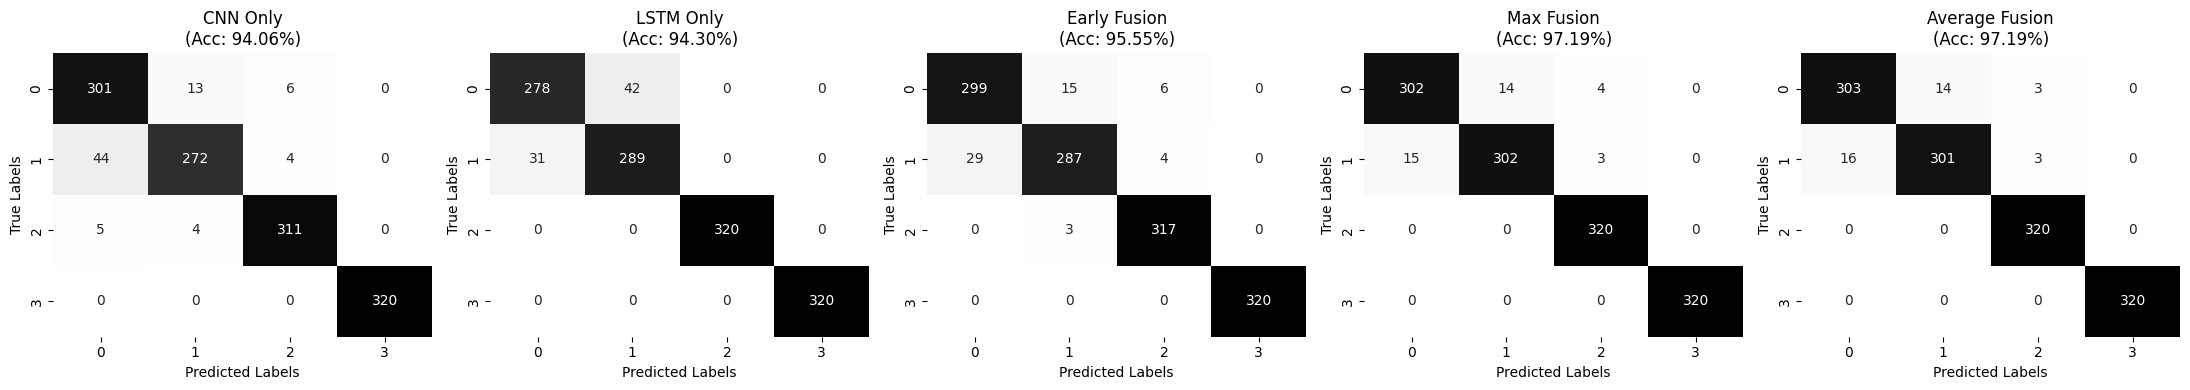

In [7]:

# LATE FUSION (MAX & AVERAGE)

t0 = time.time()
max_fusion_probs = np.maximum(lstm_probs, cnn_probs)
max_fusion_preds = np.argmax(max_fusion_probs, axis=1)
max_fusion_acc   = accuracy_score(y_test, max_fusion_preds)

avg_fusion_probs = (lstm_probs + cnn_probs) / 2.0
avg_fusion_preds = np.argmax(avg_fusion_probs, axis=1)
avg_fusion_acc   = accuracy_score(y_test, avg_fusion_preds)
late_fusion_lat  = lstm_lat + cnn_lat

print(f"==================== MAX FUSION RESULTS ====================")
print(f"Test Accuracy             : {max_fusion_acc*100:.2f}%")
print(classification_report(y_test, max_fusion_preds, target_names=class_names, digits=2))

print(f"==================== AVERAGE FUSION RESULTS ====================")
print(f"Test Accuracy             : {avg_fusion_acc*100:.2f}%")
print(classification_report(y_test, avg_fusion_preds, target_names=class_names, digits=2))


# EARLY FUSION

lstm_feat_extractor = models.Model(inputs=lstm_model.input, outputs=lstm_model.get_layer("lstm_layer").output)
cnn_feat_extractor  = models.Model(inputs=cnn_model.input, outputs=cnn_model.layers[-2].output)

print("Extracting feature vectors from pre-trained CNN and LSTM models...")
t_ext = time.time()
F_lstm_train = lstm_feat_extractor.predict(X_sens_train_lstm, verbose=0)
F_lstm_val   = lstm_feat_extractor.predict(X_sens_val_lstm, verbose=0)
F_lstm_test  = lstm_feat_extractor.predict(X_sens_test_lstm, verbose=0)

F_cnn_train  = cnn_feat_extractor.predict(X_img_train, verbose=0)
F_cnn_val    = cnn_feat_extractor.predict(X_img_val, verbose=0)
F_cnn_test   = cnn_feat_extractor.predict(X_img_test, verbose=0)
print(f"Feature extraction complete ({time.time() - t_ext:.1f} s). Training Early Fusion classifier...")

inp_lstm_f = layers.Input(shape=(F_lstm_train.shape[1],), name="lstm_feature_vector")
inp_cnn_f  = layers.Input(shape=(F_cnn_train.shape[1],), name="cnn_feature_vector")

merged = layers.Concatenate(name="concatenation")([inp_lstm_f, inp_cnn_f])
x = layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(0.005))(merged)
out = layers.Dense(4, activation='softmax', name="fused_output")(x)

early_fusion_model = models.Model(inputs=[inp_lstm_f, inp_cnn_f], outputs=out, name="Early_Fusion")
early_fusion_model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001, weight_decay=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

t0 = time.time()
history_ef = early_fusion_model.fit(
    [F_lstm_train, F_cnn_train], y_train,
    validation_data=([F_lstm_val, F_cnn_val], y_val),
    epochs=100,
    batch_size=32,
    callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
    verbose=0
)
ef_train_time = time.time() - t0

ef_probs, ef_preds, ef_acc, ef_head_lat = evaluate_and_log(
    early_fusion_model, [F_lstm_test, F_cnn_test], y_test, "EARLY FUSION (CNN + LSTM)", ef_train_time
)
total_ef_latency = lstm_lat + cnn_lat + ef_head_lat
print(f"Early Fusion Total End-to-End Inference Latency: {total_ef_latency:.3f} ms/sample")

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
model_list = [
    ("CNN Only", cnn_preds, cnn_acc),
    ("LSTM Only", lstm_preds, lstm_acc),
    ("Early Fusion", ef_preds, ef_acc),
    ("Max Fusion", max_fusion_preds, max_fusion_acc),
    ("Average Fusion", avg_fusion_preds, avg_fusion_acc)
]

for ax, (name, preds, acc_val) in zip(axes, model_list):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greys', cbar=False, ax=ax,
                xticklabels=[0, 1, 2, 3], yticklabels=[0, 1, 2, 3])
    ax.set_title(f"{name}\n(Acc: {acc_val*100:.2f}%)")
    ax.set_xlabel("Predicted Labels")
    ax.set_ylabel("True Labels")

plt.tight_layout()
plt.show()

In [11]:

tf.random.set_seed(42)
np.random.seed(42)


# MODALITY CORRUPTION AUGMENTATION FOR ROBUST TRAINING
# Add random sensor or camera noise to ~50% of the augmented copies so the
# gating mechanism learns to suppress unreliable/corrupted modalities.

def create_robust_training_data(F_lstm, F_cnn, y, copies=3):
    X_l_list, X_c_list, y_list = [F_lstm], [F_cnn], [y]
    n = len(y)
    for _ in range(copies - 1):
        l_copy = F_lstm.copy()
        c_copy = F_cnn.copy()

        # 25% probability of noisy/faulty gas sensor
        mask_l = np.random.rand(n, 1) < 0.25
        noise_l = np.random.normal(0, 2.5, l_copy.shape)
        l_copy = np.where(mask_l, l_copy + noise_l, l_copy)

        # 25% probability of noisy/occluded thermal camera (mutually exclusive with sensor fault)
        mask_c = (np.random.rand(n, 1) < 0.25) & (~mask_l)
        noise_c = np.random.normal(0, 2.5, c_copy.shape)
        c_copy = np.where(mask_c, c_copy * 0.1 + noise_c, c_copy)

        X_l_list.append(l_copy)
        X_c_list.append(c_copy)
        y_list.append(y)

    return np.vstack(X_l_list), np.vstack(X_c_list), np.concatenate(y_list)

F_lstm_tr_aug, F_cnn_tr_aug, y_tr_aug = create_robust_training_data(F_lstm_train, F_cnn_train, y_train)


# PROPOSED MODEL: GATED MULTIMODAL FUSION (GMU) & ABLATION MODEL

def build_gated_fusion_model(use_gating=True, name="Proposed_Gated_Fusion"):
    inp_lstm = layers.Input(shape=(F_lstm_train.shape[1],), name="lstm_feat")
    inp_cnn  = layers.Input(shape=(F_cnn_train.shape[1],), name="cnn_feat")


    h_lstm = layers.Dense(32, activation='tanh', kernel_regularizer=regularizers.l2(0.002))(inp_lstm)
    h_lstm = layers.BatchNormalization()(h_lstm)

    h_cnn  = layers.Dense(32, activation='tanh', kernel_regularizer=regularizers.l2(0.002))(inp_cnn)
    h_cnn  = layers.BatchNormalization()(h_cnn)

    if use_gating:

        concat_for_gate = layers.Concatenate()([h_lstm, h_cnn])
        gate_z = layers.Dense(32, activation='sigmoid', name="modality_gate")(concat_for_gate)


        inv_gate = layers.Lambda(lambda z: 1.0 - z)(gate_z)
        gated_lstm = layers.Multiply()([gate_z, h_lstm])
        gated_cnn  = layers.Multiply()([inv_gate, h_cnn])
        fused = layers.Add(name="gated_fusion_vector")([gated_lstm, gated_cnn])
    else:

        fused = layers.Add(name="ungated_add_vector")([h_lstm, h_cnn])

    x = layers.Dropout(0.2)(fused)
    x = layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(0.002))(x)
    out = layers.Dense(4, activation='softmax')(x)

    model = models.Model(inputs=[inp_lstm, inp_cnn], outputs=out, name=name)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.001, weight_decay=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


gated_model = build_gated_fusion_model(use_gating=True, name="Proposed_Gated_Fusion")
t0 = time.time()
gated_model.fit(
    [F_lstm_tr_aug, F_cnn_tr_aug], y_tr_aug,
    validation_data=([F_lstm_val, F_cnn_val], y_val),
    epochs=80, batch_size=32,
    callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
    verbose=0
)
gated_train_time = time.time() - t0


ablation_model = build_gated_fusion_model(use_gating=False, name="Ablation_No_Gate")
ablation_model.fit(
    [F_lstm_train, F_cnn_train], y_train,
    validation_data=([F_lstm_val, F_cnn_val], y_val),
    epochs=80, batch_size=32,
    callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
    verbose=0
)


gated_probs, gated_preds, gated_acc, gated_head_lat = evaluate_and_log(
    gated_model, [F_lstm_test, F_cnn_test], y_test, "PROPOSED GATED FUSION (GMU)", gated_train_time
)


# STRESS TEST: COMPARISON UNDER SENSOR FAULT AND NOISE

np.random.seed(42)

F_lstm_corrupted = F_lstm_test + np.random.normal(0, 2.0, F_lstm_test.shape)


F_lstm_missing = np.zeros_like(F_lstm_test)


F_cnn_corrupted = F_cnn_test * 0.1 + np.random.normal(0, 2.0, F_cnn_test.shape)

scenarios = {
    "1. Clean Input": (F_lstm_test, F_cnn_test),
    "2. Noisy Gas Sensor": (F_lstm_corrupted, F_cnn_test),
    "3. Missing Gas Sensor": (F_lstm_missing, F_cnn_test),
    "4. Corrupted Thermal Camera": (F_lstm_test, F_cnn_corrupted)
}

results_table = []
for sc_name, (l_in, c_in) in scenarios.items():
    acc_base = accuracy_score(y_test, np.argmax(early_fusion_model.predict([l_in, c_in], verbose=0), axis=1)) * 100
    acc_avg  = accuracy_score(y_test, np.argmax((lstm_model.predict(X_sens_test_lstm, verbose=0) if "Sensor" not in sc_name else np.full((1280, 4), 0.25)) + cnn_probs, axis=1)) * 100
    acc_abl  = accuracy_score(y_test, np.argmax(ablation_model.predict([l_in, c_in], verbose=0), axis=1)) * 100
    acc_prop = accuracy_score(y_test, np.argmax(gated_model.predict([l_in, c_in], verbose=0), axis=1)) * 100

    results_table.append({
        "Test Scenario": sc_name,
        "Baseline Early Fusion (%)": round(acc_base, 2),
        "Ablation (No-Gate) (%)": round(acc_abl, 2),
        "Proposed Gated Fusion (%)": round(acc_prop, 2),
        "Diff (Proposed - Baseline)": f"{acc_prop - acc_base:+.2f}%"
    })

df_results = pd.DataFrame(results_table)
print("\n================CLEAN VS. CORRUPTED CONDITIONS COMPARISON TABLE ================")
display(df_results)


==================== PROPOSED GATED FUSION (GMU) RESULTS ====================
Test Accuracy             : 96.48%
Total Training Time       : 48.30 seconds
Inference Latency         : 0.296 ms/sample
Total Parameters          : 5,796

Class-wise Metrics :
              precision    recall  f1-score   support

       NoGas       0.93      0.93      0.93       320
     Perfume       0.94      0.94      0.94       320
       Smoke       0.98      0.99      0.99       320
     Mixture       1.00      1.00      1.00       320

    accuracy                           0.96      1280
   macro avg       0.96      0.96      0.96      1280
weighted avg       0.96      0.96      0.96      1280


================CLEAN VS. CORRUPTED CONDITIONS COMPARISON TABLE ================


,Test Scenario,Baseline Early Fusion (%),Ablation (No-Gate) (%),Proposed Gated Fusion (%),Diff (Proposed - Baseline)
0,1. Clean Input,95.55,98.05,96.48,+0.94%
1,2. Noisy Gas Sensor,91.33,43.28,93.67,+2.34%
2,3. Missing Gas Sensor,95.08,91.95,94.61,-0.47%
3,4. Corrupted Thermal Camera,45.70,80.70,90.94,+45.23%


/tmp/ipykernel_2040/1558915907.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax2.boxplot([gate_clean, gate_noisy_sen, gate_noisy_cam],


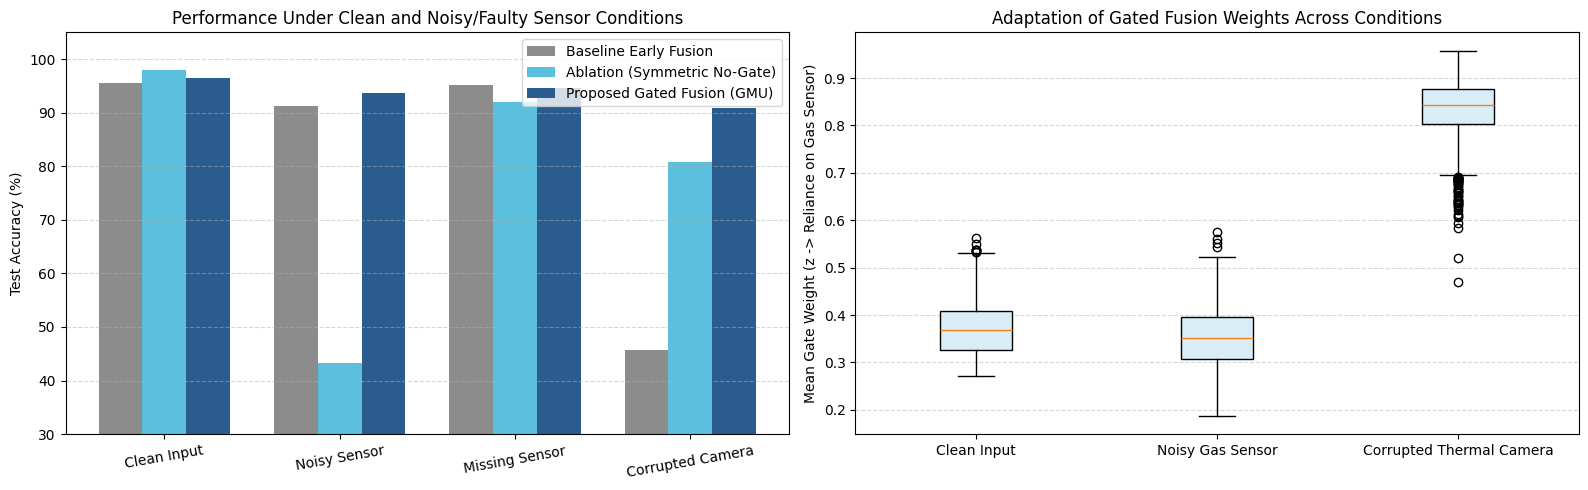

================ UNCERTAINTY (95% CI) ANALYSIS ================
LSTM Only (Reproduced)    : 94.30% ± 0.66%  (95% CI: [92.97%, 95.70%])
CNN Only (Reproduced)     : 94.09% ± 0.66%  (95% CI: [92.81%, 95.39%])
Baseline Early Fusion     : 95.56% ± 0.57%  (95% CI: [94.38%, 96.56%])
Ablation (Symmetric Add)  : 98.07% ± 0.38%  (95% CI: [97.34%, 98.75%])
Proposed Gated Fusion     : 96.50% ± 0.50%  (95% CI: [95.47%, 97.34%])

================ FAILURE ANALYSIS ================
Total Test Samples: 1280 | Misclassified Samples: 45

Most Frequent Misclassification Pairs:
True: Perfume -> Pred: NoGas    19
True: NoGas -> Pred: Perfume    17
True: NoGas -> Pred: Smoke       4
True: Smoke -> Pred: Perfume     2
True: Smoke -> Pred: NoGas       2
True: Perfume -> Pred: Smoke     1
Name: count, dtype: int64

Inspection of Sample Misclassifications (First 5 Errors):


,Test_Index,True_Class,Predicted_Class,Model_Confidence (Max Prob),LSTM_Prediction,CNN_Prediction
0,13,Smoke,Perfume,0.939,Smoke,Smoke
1,23,NoGas,Perfume,0.520,Perfume,NoGas
2,32,NoGas,Perfume,0.644,Perfume,NoGas
3,43,NoGas,Perfume,0.679,Perfume,NoGas
4,44,NoGas,Perfume,1.000,NoGas,Perfume


In [12]:

# VISUALIZATION: STRESS TEST COMPARISON CHART & GATE BEHAVIOR

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

x_pos = np.arange(len(df_results))
width = 0.25

ax1.bar(x_pos - width, df_results["Baseline Early Fusion (%)"], width, label="Baseline Early Fusion", color="#8c8c8c")
ax1.bar(x_pos,         df_results["Ablation (No-Gate) (%)"],    width, label="Ablation (Symmetric No-Gate)", color="#5bc0de")
ax1.bar(x_pos + width, df_results["Proposed Gated Fusion (%)"], width, label="Proposed Gated Fusion (GMU)", color="#2b5c8f")

ax1.set_ylabel("Test Accuracy (%)")
ax1.set_title("Performance Under Clean and Noisy/Faulty Sensor Conditions")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(["Clean Input", "Noisy Sensor", "Missing Sensor", "Corrupted Camera"], rotation=10)
ax1.set_ylim(30, 105)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
ax1.legend()

gate_extractor = models.Model(inputs=gated_model.input, outputs=gated_model.get_layer("modality_gate").output)

gate_clean     = gate_extractor.predict([F_lstm_test, F_cnn_test], verbose=0).mean(axis=1)
gate_noisy_sen = gate_extractor.predict([F_lstm_corrupted, F_cnn_test], verbose=0).mean(axis=1)
gate_noisy_cam = gate_extractor.predict([F_lstm_test, F_cnn_corrupted], verbose=0).mean(axis=1)

ax2.boxplot([gate_clean, gate_noisy_sen, gate_noisy_cam],
            labels=["Clean Input", "Noisy Gas Sensor", "Corrupted Thermal Camera"],
            patch_artist=True, boxprops=dict(facecolor="#d9edf7"))
ax2.set_ylabel("Mean Gate Weight (z -> Reliance on Gas Sensor)")
ax2.set_title("Adaptation of Gated Fusion Weights Across Conditions")
ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("section4_improvement_analysis.png", dpi=300)
plt.show()


# UNCERTAINTY ANALYSIS

def bootstrap_ci(y_true, y_pred, n_bootstraps=1000, seed=42):
    rng = np.random.RandomState(seed)
    scores = []
    n = len(y_true)
    for _ in range(n_bootstraps):
        idx = rng.randint(0, n, n)
        scores.append(accuracy_score(y_true[idx], y_pred[idx]) * 100)
    return np.mean(scores), np.std(scores), np.percentile(scores, 2.5), np.percentile(scores, 97.5)

print("================ UNCERTAINTY (95% CI) ANALYSIS ================")
for m_name, m_preds in [
    ("LSTM Only (Reproduced)", lstm_preds),
    ("CNN Only (Reproduced)", cnn_preds),
    ("Baseline Early Fusion", ef_preds),
    ("Ablation (Symmetric Add)", np.argmax(ablation_model.predict([F_lstm_test, F_cnn_test], verbose=0), axis=1)),
    ("Proposed Gated Fusion", gated_preds)
]:
    mean_acc, std_acc, ci_low, ci_high = bootstrap_ci(y_test, m_preds)
    print(f"{m_name:26s}: {mean_acc:.2f}% ± {std_acc:.2f}%  (95% CI: [{ci_low:.2f}%, {ci_high:.2f}%])")


# FAILURE ANALYSIS (MISCLASSIFIED SAMPLES INSPECTION)

errors_idx = np.where(gated_preds != y_test)[0]
print(f"\n================ FAILURE ANALYSIS ================")
print(f"Total Test Samples: {len(y_test)} | Misclassified Samples: {len(errors_idx)}")

error_pairs = pd.Series([
    f"True: {class_names[y_test[i]]} -> Pred: {class_names[gated_preds[i]]}"
    for i in errors_idx
]).value_counts()
print("\nMost Frequent Misclassification Pairs:")
print(error_pairs)

error_details = []
for i in errors_idx[:5]:
    error_details.append({
        "Test_Index": i,
        "True_Class": class_names[y_test[i]],
        "Predicted_Class": class_names[gated_preds[i]],
        "Model_Confidence (Max Prob)": round(float(np.max(gated_probs[i])), 3),
        "LSTM_Prediction": class_names[lstm_preds[i]],
        "CNN_Prediction": class_names[cnn_preds[i]]
    })
print("\nInspection of Sample Misclassifications (First 5 Errors):")
display(pd.DataFrame(error_details))

In [13]:
# Save result tables, plots, and model weights for the report and GitHub repository
df_results.to_csv("experimental_results.csv", index=False)
early_fusion_model.save("baseline_early_fusion.keras")
gated_model.save("proposed_gated_fusion.keras")
print("All result tables, plots, and model weights have been successfully saved!")

All result tables, plots, and model weights have been successfully saved!
